In [79]:
import pandas as pd
import numpy as np
from sklearn.datasets import make_classification

In [80]:
X,y = make_classification(n_features=5, n_informative=5, n_redundant=0, n_clusters_per_class=1)

In [81]:
df = pd.DataFrame(X, columns=['col1','col2','col3','col4','col5'])
df['target'] = y
df.head()

,col1,col2,col3,col4,col5,target
0,-1.974463,1.059690,-2.550080,0.455208,-2.712632,0
1,-0.375449,0.509616,-0.121424,1.103660,-0.192605,0
2,-0.550847,-0.237467,-0.236325,0.537703,1.025324,1
3,-0.931135,-1.052961,-1.021766,0.504156,1.049117,1
4,-2.003736,0.718472,-0.495012,1.979547,-1.133706,0


In [82]:
def sample_row(df,percent):
    return df.sample(int(percent*df.shape[0]),replace=True)

In [83]:
import random
def sample_cols(df,percent):
    cols = random.sample(df.columns.tolist()[:-1], int(percent*(df.shape[1]-1)))
    new_df = df[cols]
    new_df['target'] = df['target']
    return new_df

In [84]:
def combined_sampling(df,row_percent,col_percent):
    new_sample = sample_row(df,row_percent)
    return sample_cols(new_sample,col_percent)

# using Rowsampling

In [85]:
df1 = sample_row(df,0.2)
df2 = sample_row(df,0.2)
df3 = sample_row(df,0.2)

In [86]:
from sklearn.tree import DecisionTreeClassifier
clf1 = DecisionTreeClassifier()
clf2 = DecisionTreeClassifier()
clf3 = DecisionTreeClassifier()

In [87]:
clf1.fit(df1.iloc[:,0:5],df1.iloc[:,-1])
clf2.fit(df2.iloc[:,0:5],df2.iloc[:,-1])
clf3.fit(df3.iloc[:,0:5],df3.iloc[:,-1])

DecisionTreeClassifier()

In [88]:
from sklearn.tree import plot_tree

[Text(0.3333333333333333, 0.875, 'x[4] <= 0.776\ngini = 0.375\nsamples = 20\nvalue = [5, 15]'),
 Text(0.16666666666666666, 0.625, 'gini = 0.0\nsamples = 4\nvalue = [4, 0]'),
 Text(0.25, 0.75, 'True  '),
 Text(0.5, 0.625, 'x[3] <= 1.946\ngini = 0.117\nsamples = 16\nvalue = [1, 15]'),
 Text(0.41666666666666663, 0.75, '  False'),
 Text(0.3333333333333333, 0.375, 'gini = 0.0\nsamples = 13\nvalue = [0, 13]'),
 Text(0.6666666666666666, 0.375, 'x[2] <= -1.279\ngini = 0.444\nsamples = 3\nvalue = [1, 2]'),
 Text(0.5, 0.125, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.8333333333333334, 0.125, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]')]

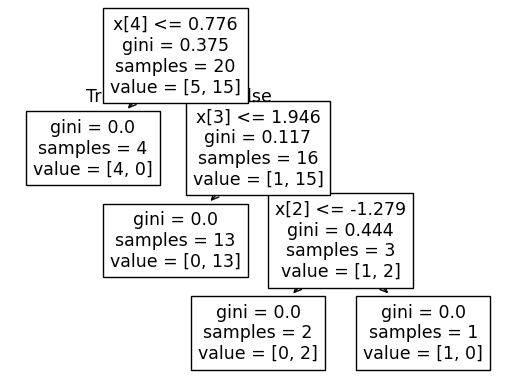

In [89]:
plot_tree(clf1)

[Text(0.3333333333333333, 0.875, 'x[1] <= 0.157\ngini = 0.455\nsamples = 20\nvalue = [7, 13]'),
 Text(0.16666666666666666, 0.625, 'gini = 0.0\nsamples = 12\nvalue = [0, 12]'),
 Text(0.25, 0.75, 'True  '),
 Text(0.5, 0.625, 'x[4] <= -0.122\ngini = 0.219\nsamples = 8\nvalue = [7, 1]'),
 Text(0.41666666666666663, 0.75, '  False'),
 Text(0.3333333333333333, 0.375, 'gini = 0.0\nsamples = 6\nvalue = [6, 0]'),
 Text(0.6666666666666666, 0.375, 'x[3] <= 3.541\ngini = 0.5\nsamples = 2\nvalue = [1, 1]'),
 Text(0.5, 0.125, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.8333333333333334, 0.125, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]')]

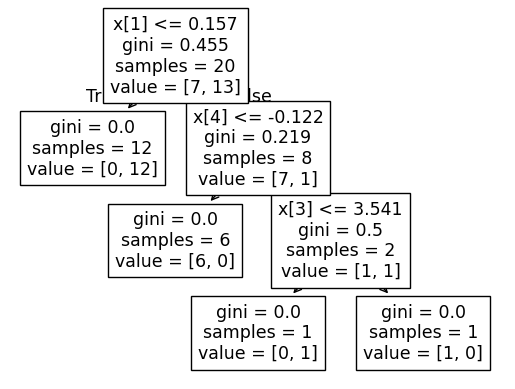

In [90]:
plot_tree(clf2)

[Text(0.5, 0.75, 'x[1] <= -0.274\ngini = 0.48\nsamples = 20\nvalue = [12, 8]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 8\nvalue = [0, 8]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 12\nvalue = [12, 0]'),
 Text(0.625, 0.5, '  False')]

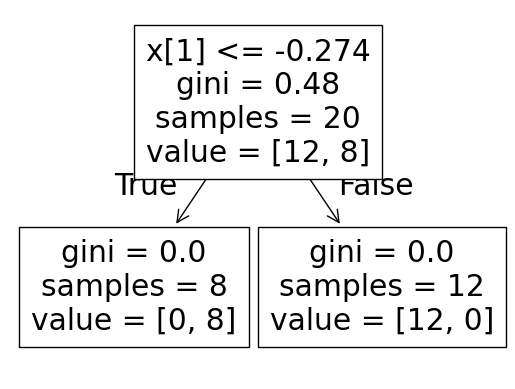

In [91]:
plot_tree(clf3)

In [92]:
clf1.predict(np.array([0.958393,0.628581,1.278932,0.395442,-1.011745]).reshape(1,5))

/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [93]:
clf2.predict(np.array([0.958393,0.628581,1.278932,0.395442,-1.011745]).reshape(1,5))

/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [94]:
clf3.predict(np.array([0.958393,0.628581,1.278932,0.395442,-1.011745]).reshape(1,5))

/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [95]:
df1 = sample_cols(df,0.7)
df2 = sample_cols(df,0.7)
df3 = sample_cols(df,0.7)
y = df.iloc[:,-1]

/var/folders/lh/42glnkrn40x_dxrvypysh9w00000gn/T/ipykernel_75020/2567730909.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']
/var/folders/lh/42glnkrn40x_dxrvypysh9w00000gn/T/ipykernel_75020/2567730909.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['target'] = df['target']
/var/folders/lh/42glnkrn40x_dxrvypysh9w00000gn/T/ipykernel_75020/2567730909.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row

In [96]:
clf1 = DecisionTreeClassifier()
clf2 = DecisionTreeClassifier()
clf3 = DecisionTreeClassifier()

In [97]:
clf1.fit(df1.iloc[:,0:3],df1.iloc[:,-1])
clf2.fit(df2.iloc[:,0:3],df2.iloc[:,-1])
clf3.fit(df3.iloc[:,0:3],df3.iloc[:,-1])

DecisionTreeClassifier()

[Text(0.6983695652173914, 0.9642857142857143, 'x[2] <= 0.46\ngini = 0.5\nsamples = 100\nvalue = [50, 50]'),
 Text(0.5489130434782609, 0.8928571428571429, 'x[1] <= -0.302\ngini = 0.492\nsamples = 87\nvalue = [49, 38]'),
 Text(0.6236413043478262, 0.9285714285714286, 'True  '),
 Text(0.3804347826086957, 0.8214285714285714, 'x[0] <= -0.047\ngini = 0.5\nsamples = 74\nvalue = [37, 37]'),
 Text(0.17391304347826086, 0.75, 'x[2] <= -2.466\ngini = 0.32\nsamples = 15\nvalue = [3, 12]'),
 Text(0.08695652173913043, 0.6785714285714286, 'x[1] <= -2.023\ngini = 0.444\nsamples = 3\nvalue = [2, 1]'),
 Text(0.043478260869565216, 0.6071428571428571, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.13043478260869565, 0.6071428571428571, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.2608695652173913, 0.6785714285714286, 'x[2] <= -1.374\ngini = 0.153\nsamples = 12\nvalue = [1, 11]'),
 Text(0.21739130434782608, 0.6071428571428571, 'x[0] <= -0.391\ngini = 0.375\nsamples = 4\nvalue = [1, 3]'),
 Text(0.

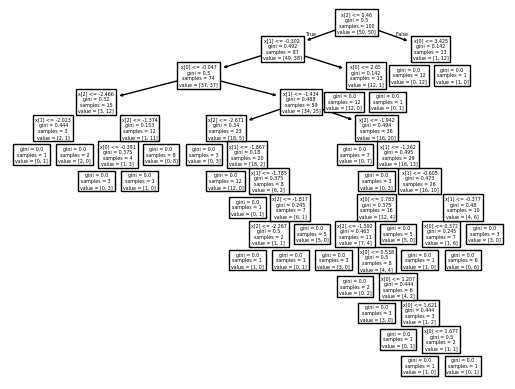

In [98]:
plot_tree(clf1)

[Text(0.34615384615384615, 0.9, 'x[1] <= -0.01\ngini = 0.5\nsamples = 100\nvalue = [50, 50]'),
 Text(0.2692307692307692, 0.7, 'gini = 0.0\nsamples = 40\nvalue = [40, 0]'),
 Text(0.3076923076923077, 0.8, 'True  '),
 Text(0.4230769230769231, 0.7, 'x[0] <= 0.664\ngini = 0.278\nsamples = 60\nvalue = [10, 50]'),
 Text(0.3846153846153846, 0.8, '  False'),
 Text(0.15384615384615385, 0.5, 'x[2] <= 3.119\ngini = 0.043\nsamples = 46\nvalue = [1, 45]'),
 Text(0.07692307692307693, 0.3, 'gini = 0.0\nsamples = 42\nvalue = [0, 42]'),
 Text(0.23076923076923078, 0.3, 'x[2] <= 3.255\ngini = 0.375\nsamples = 4\nvalue = [1, 3]'),
 Text(0.15384615384615385, 0.1, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.3076923076923077, 0.1, 'gini = 0.0\nsamples = 3\nvalue = [0, 3]'),
 Text(0.6923076923076923, 0.5, 'x[1] <= 1.101\ngini = 0.459\nsamples = 14\nvalue = [9, 5]'),
 Text(0.5384615384615384, 0.3, 'x[2] <= 2.421\ngini = 0.198\nsamples = 9\nvalue = [8, 1]'),
 Text(0.46153846153846156, 0.1, 'gini = 0.0\ns

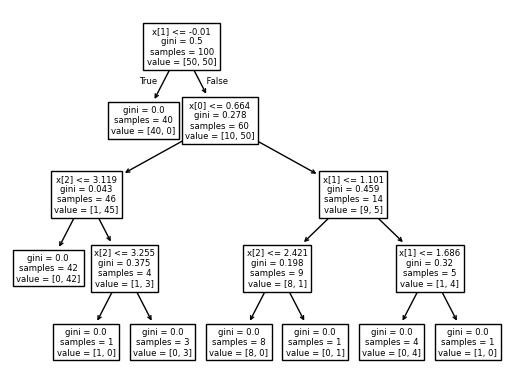

In [99]:
plot_tree(clf2)

[Text(0.5416666666666666, 0.9375, 'x[2] <= -0.01\ngini = 0.5\nsamples = 100\nvalue = [50, 50]'),
 Text(0.4583333333333333, 0.8125, 'gini = 0.0\nsamples = 40\nvalue = [40, 0]'),
 Text(0.5, 0.875, 'True  '),
 Text(0.625, 0.8125, 'x[0] <= -0.302\ngini = 0.278\nsamples = 60\nvalue = [10, 50]'),
 Text(0.5833333333333333, 0.875, '  False'),
 Text(0.4166666666666667, 0.6875, 'x[2] <= 1.895\ngini = 0.183\nsamples = 49\nvalue = [5, 44]'),
 Text(0.3333333333333333, 0.5625, 'x[2] <= 0.437\ngini = 0.153\nsamples = 48\nvalue = [4, 44]'),
 Text(0.16666666666666666, 0.4375, 'x[0] <= -0.473\ngini = 0.5\nsamples = 4\nvalue = [2, 2]'),
 Text(0.08333333333333333, 0.3125, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0.25, 0.3125, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.5, 0.4375, 'x[1] <= -0.33\ngini = 0.087\nsamples = 44\nvalue = [2, 42]'),
 Text(0.4166666666666667, 0.3125, 'gini = 0.0\nsamples = 31\nvalue = [0, 31]'),
 Text(0.5833333333333334, 0.3125, 'x[0] <= -1.674\ngini = 0.26\nsampl

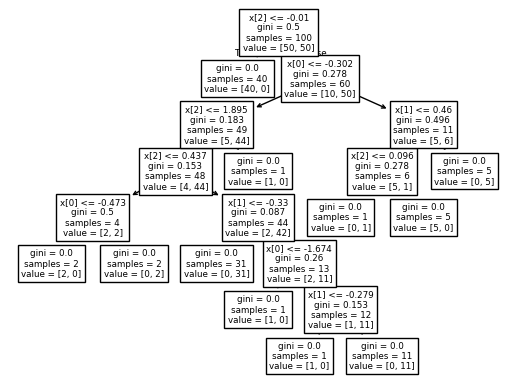

In [100]:
plot_tree(clf3)

In [101]:
print(df1.columns.tolist())
print(df2.columns.tolist())
print(df3.columns.tolist())

['col4', 'col1', 'col3', 'target']
['col2', 'col5', 'col4', 'target']
['col1', 'col3', 'col5', 'target']


In [103]:
print(clf1.predict(np.array([0.958393,0.628581,1.278932]).reshape(1,3)))
print(clf2.predict(np.array([0.958393,0.628581,1.278932]).reshape(1,3)))
print(clf3.predict(np.array([0.958393,0.628581,1.278932]).reshape(1,3)))

[1]
[0]
[1]


/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
